<a href="https://colab.research.google.com/github/walbyn504/Laboratorio4-DW/blob/main/lab4_IC2025.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Laboratorio 4 · Análisis exploratorio de datos (EDA)

**Universidad Técnica Nacional** · Minería de Datos ISW-911 · III Cuatrimestre 2026

**Integrantes del grupo**

| Nombre | Apellidos
|---|---|
| Jimena | Jara Rojas |
| Walbyn | González Sequiera |
| Fiorella | Lazo Reyes |
| Seidy | Alanis Balladares |

**Conjunto de datos:** Data Warehouse de la cadena de supermercados Dunnhumby (`laboratorio4_dw.csv.xz`).
Se lee directamente desde el repositorio público de GitHub: https://github.com/walbyn504/Laboratorio4-Mineria

**Contenido**

1. Carga del conjunto de datos desde GitHub
2. Características principales (funciones básicas)
3. Nombres de columnas en español
4. Valores nulos
5. Valores atípicos
6. Funciones de imputación
7. Conversión de tipos de datos
8. Conversión de variables categóricas a numéricas
9. Estandarización
10. Correlación
11. Variable dependiente y modelo candidato
12. Guardado de `data_process.csv`

## 1. Carga del conjunto de datos desde GitHub

El archivo está comprimido en formato `xz` para no superar el límite de tamaño de GitHub.
Pandas lo descomprime al leerlo, así que se usa el enlace *raw* del repositorio público.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", None)

url = (
    "https://raw.githubusercontent.com/walbyn504/"
    "Laboratorio4-Mineria/main/laboratorio4_dw.csv.xz"
)

ventas = pd.read_csv(url, compression="xz")

print("Filas:", ventas.shape[0])
print("Columnas:", ventas.shape[1])
display(ventas.head())

Filas: 2595732
Columnas: 16


,sale_detail_id,basket_id,store_id,calendar_date,department,brand,category,household_size,has_promotion,display_type,household_in_active_campaign,quantity,sales_value,retail_discount,coupon_discount,coupon_match_discount
0,1,27601281299,436,2004-02-20,grocery,national,sald drsng/sndwch sprd,2,Undetermined,No causal data,Not in campaign,1,3.99,0.00,0.0,0.0
1,2,27601281299,436,2004-02-20,grocery,national,cheese,2,Undetermined,No causal data,Not in campaign,1,2.99,0.00,0.0,0.0
2,3,27601281299,436,2004-02-20,grocery,private,eggs,2,Undetermined,No causal data,Not in campaign,1,1.09,-0.30,0.0,0.0
3,4,27601281299,436,2004-02-20,deli,national,deli meats,2,Undetermined,No causal data,Not in campaign,1,3.71,-0.62,0.0,0.0
4,5,27601281299,436,2004-02-20,grocery,private,ice cream/milk/sherbts,2,Undetermined,No causal data,Not in campaign,1,2.79,-1.20,0.0,0.0


## 2. Características principales del conjunto de datos

Se usan las funciones básicas de pandas: `shape`, `head`, `tail`, `sample`, `info`, `dtypes`,
`nunique`, `describe`, `duplicated` y `value_counts`.

In [ ]:
ventas.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2595732 entries, 0 to 2595731
Data columns (total 16 columns):
 #   Column                        Dtype  
---  ------                        -----  
 0   sale_detail_id                int64  
 1   basket_id                     int64  
 2   store_id                      int64  
 3   calendar_date                 object 
 4   department                    object 
 5   brand                         object 
 6   category                      object 
 7   household_size                object 
 8   has_promotion                 object 
 9   display_type                  object 
 10  household_in_active_campaign  object 
 11  quantity                      int64  
 12  sales_value                   float64
 13  retail_discount               float64
 14  coupon_discount               float64
 15  coupon_match_discount         float64
dtypes: float64(4), int64(4), object(8)
memory usage: 316.9+ MB


In [ ]:
resumen_columnas = pd.DataFrame({
    "tipo": ventas.dtypes.astype(str),
    "valores_unicos": ventas.nunique(),
    "ejemplo": ventas.iloc[0],
})
display(resumen_columnas)

,tipo,valores_unicos,ejemplo
sale_detail_id,int64,2595732,1
basket_id,int64,276484,27601281299
store_id,int64,582,436
calendar_date,object,711,2004-02-20
department,object,44,grocery
brand,object,2,national
category,object,308,sald drsng/sndwch sprd
household_size,object,6,2
has_promotion,object,2,Undetermined
display_type,object,20,No causal data


In [ ]:
display(ventas.tail())
display(ventas.sample(5, random_state=42))

,sale_detail_id,basket_id,store_id,calendar_date,department,brand,category,household_size,has_promotion,display_type,household_in_active_campaign,quantity,sales_value,retail_discount,coupon_discount,coupon_match_discount
2595727,2595728,42250641157,447,2005-12-08,drug gm,private,cookware & bakeware,No demographic profile,Undetermined,No causal data,Not in campaign,1,3.19,-0.80,0.0,0.0
2595728,2595729,42250641157,447,2005-12-08,produce,national,broccoli/cauliflower,No demographic profile,Undetermined,No causal data,Not in campaign,1,1.99,0.00,0.0,0.0
2595729,2595730,42250641157,447,2005-12-08,grocery,national,frozen bread/dough,No demographic profile,Undetermined,No causal data,Not in campaign,1,2.59,-1.00,0.0,0.0
2595730,2595731,42250641157,447,2005-12-08,grocery,national,cold cereal,No demographic profile,Undetermined,No causal data,Not in campaign,1,2.77,-3.02,-1.0,0.0
2595731,2595732,42250641157,447,2005-12-08,nutrition,national,dried fruit,No demographic profile,Undetermined,No causal data,Not in campaign,1,1.50,-1.49,0.0,0.0


,sale_detail_id,basket_id,store_id,calendar_date,department,brand,category,household_size,has_promotion,display_type,household_in_active_campaign,quantity,sales_value,retail_discount,coupon_discount,coupon_match_discount
2386038,2386039,31527743525,372,2004-11-01,grocery,national,margarines,5+,Undetermined,No causal data,In campaign,1,2.29,0.00,0.0,0.0
1578659,1578660,40447558047,412,2005-07-30,produce,national,popcorn,No demographic profile,Undetermined,No causal data,Not in campaign,2,3.00,-2.98,0.0,0.0
1837340,1837341,33095036416,338,2005-02-16,grocery,national,water - carbonated/flvrd drink,3,Undetermined,No causal data,In campaign,1,0.99,0.00,0.0,0.0
260939,260940,32445820269,372,2005-01-03,grocery,national,bag snacks,2,Undetermined,No causal data,Not in campaign,0,0.00,0.00,0.0,0.0
2424105,2424106,32305493280,439,2004-12-28,meat-pckgd,national,hot dogs,1,Promotion,Store rear,In campaign,1,1.00,-1.19,0.0,0.0


In [ ]:
# Estadísticas de las variables numéricas
display(ventas.describe().round(2))

,sale_detail_id,basket_id,store_id,quantity,sales_value,retail_discount,coupon_discount,coupon_match_discount
count,2595732.00,2.595732e+06,2595732.00,2595732.00,2595732.00,2595732.00,2595732.00,2595732.00
mean,1297866.50,3.402620e+10,3142.67,100.43,3.10,-0.54,-0.02,-0.00
std,749323.43,4.711649e+09,8937.11,1153.44,4.18,1.25,0.22,0.04
min,1.00,2.698485e+10,1.00,0.00,0.00,-180.00,-55.93,-7.70
25%,648933.75,3.040805e+10,330.00,1.00,1.29,-0.69,0.00,0.00
50%,1297866.50,3.276081e+10,372.00,1.00,2.00,-0.01,0.00,0.00
75%,1946799.25,4.012685e+10,422.00,1.00,3.49,0.00,0.00,0.00
max,2595732.00,4.230536e+10,34280.00,89638.00,840.00,3.99,0.00,0.00


In [ ]:
# Estadísticas de las variables de texto
display(ventas.describe(exclude="number"))

,calendar_date,department,brand,category,household_size,has_promotion,display_type,household_in_active_campaign
count,2595732,2595732,2595732,2595732,2595732,2595732,2595732,2595732
unique,711,44,2,308,6,2,20,2
top,2005-11-22,grocery,national,soft drinks,No demographic profile,Undetermined,No causal data,Not in campaign
freq,7493,1646076,1849560,117532,1168429,2031958,2031958,1828306


In [ ]:
print("Filas completamente duplicadas:", ventas.duplicated().sum())
print("IDs de línea de venta repetidos:", ventas["sale_detail_id"].duplicated().sum())
print("Rango de fechas:", ventas["calendar_date"].min(), "a", ventas["calendar_date"].max())

Filas completamente duplicadas: 0
IDs de línea de venta repetidos: 0
Rango de fechas: 2004-01-01 a 2005-12-11


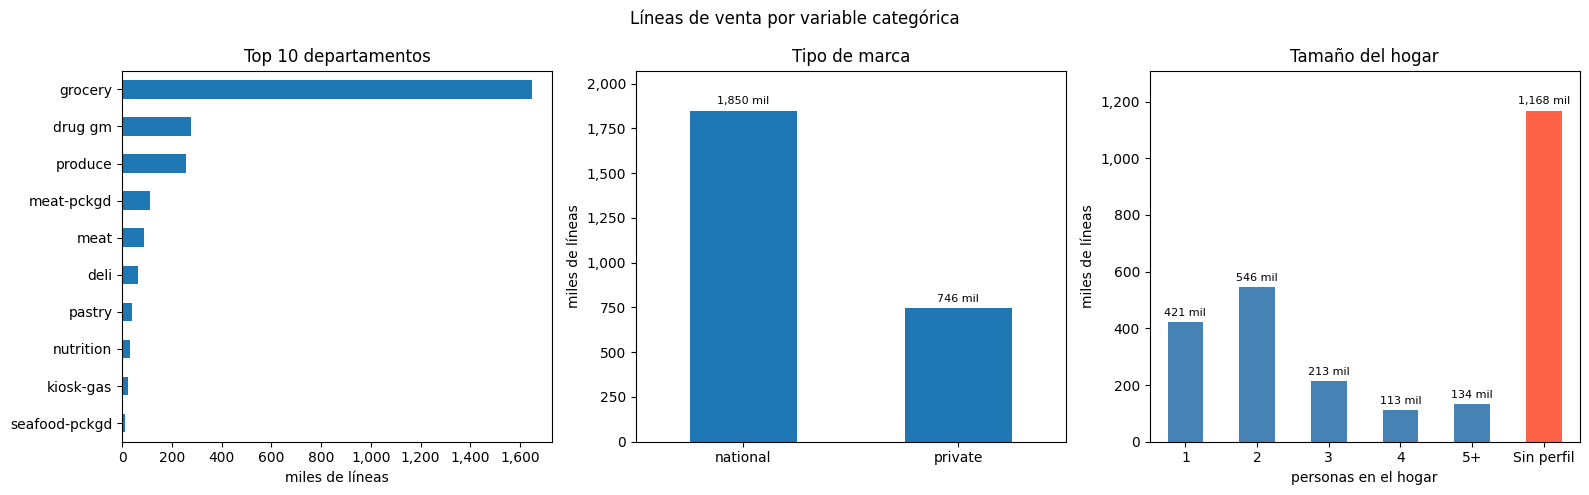

In [ ]:
from matplotlib.ticker import FuncFormatter

en_miles = FuncFormatter(lambda x, _: f"{x / 1000:,.0f}")

fig, ejes = plt.subplots(1, 3, figsize=(16, 5))

# Departamentos: barras horizontales para que los nombres se lean completos
ventas["department"].value_counts().head(10).sort_values().plot.barh(ax=ejes[0])
ejes[0].set_title("Top 10 departamentos")
ejes[0].set_ylabel("")
ejes[0].xaxis.set_major_formatter(en_miles)
ejes[0].set_xlabel("miles de líneas")

# Tipo de marca
ventas["brand"].value_counts().plot.bar(ax=ejes[1], rot=0)
ejes[1].set_title("Tipo de marca")
ejes[1].set_xlabel("")
ejes[1].yaxis.set_major_formatter(en_miles)

# Tamaño del hogar: en orden 1..5+ y etiqueta corta para "No demographic profile"
orden_hogar = ["1", "2", "3", "4", "5+", "No demographic profile"]
hogar = (
    ventas["household_size"].value_counts()
    .reindex(orden_hogar)
    .rename({"No demographic profile": "Sin perfil"})
)
colores = ["steelblue"] * 5 + ["tomato"]
hogar.plot.bar(ax=ejes[2], rot=0, color=colores)
ejes[2].set_title("Tamaño del hogar")
ejes[2].set_xlabel("personas en el hogar")
ejes[2].yaxis.set_major_formatter(en_miles)

for eje in ejes[1:]:
    eje.set_ylabel("miles de líneas")
    eje.bar_label(eje.containers[0], labels=[f"{v / 1000:,.0f} mil" for v in eje.containers[0].datavalues],
                  padding=3, fontsize=8)
    eje.margins(y=0.12)

fig.suptitle("Líneas de venta por variable categórica")
plt.tight_layout()
plt.show()

**Hallazgos.** El conjunto tiene 2 595 732 líneas de venta y 16 columnas: 3 identificadores, 1 fecha,
7 variables categóricas de texto y 5 numéricas. No hay filas duplicadas ni IDs de línea repetidos.
El departamento `grocery` concentra la mayoría de las ventas y casi tres de cada cuatro líneas son de marca nacional.
En `household_size` aparece la etiqueta *No demographic profile*, que en realidad indica un dato desconocido;
se analiza en la sección 4.

## 3. Nombres de columnas en español

In [ ]:
nombres_en_espanol = {
    "sale_detail_id": "id_linea_venta",
    "basket_id": "id_compra",
    "store_id": "id_tienda",
    "calendar_date": "fecha_venta",
    "department": "departamento",
    "brand": "tipo_marca",
    "category": "categoria",
    "household_size": "tamano_hogar",
    "has_promotion": "estado_promocion",
    "display_type": "tipo_exhibicion",
    "household_in_active_campaign": "hogar_en_campana_activa",
    "quantity": "cantidad",
    "sales_value": "importe_venta",
    "retail_discount": "descuento_tienda",
    "coupon_discount": "descuento_cupon",
    "coupon_match_discount": "igualacion_descuento_cupon",
}

ventas = ventas.rename(columns=nombres_en_espanol)
print(list(ventas.columns))
display(ventas.head())

['id_linea_venta', 'id_compra', 'id_tienda', 'fecha_venta', 'departamento', 'tipo_marca', 'categoria', 'tamano_hogar', 'estado_promocion', 'tipo_exhibicion', 'hogar_en_campana_activa', 'cantidad', 'importe_venta', 'descuento_tienda', 'descuento_cupon', 'igualacion_descuento_cupon']


,id_linea_venta,id_compra,id_tienda,fecha_venta,departamento,tipo_marca,categoria,tamano_hogar,estado_promocion,tipo_exhibicion,hogar_en_campana_activa,cantidad,importe_venta,descuento_tienda,descuento_cupon,igualacion_descuento_cupon
0,1,27601281299,436,2004-02-20,grocery,national,sald drsng/sndwch sprd,2,Undetermined,No causal data,Not in campaign,1,3.99,0.00,0.0,0.0
1,2,27601281299,436,2004-02-20,grocery,national,cheese,2,Undetermined,No causal data,Not in campaign,1,2.99,0.00,0.0,0.0
2,3,27601281299,436,2004-02-20,grocery,private,eggs,2,Undetermined,No causal data,Not in campaign,1,1.09,-0.30,0.0,0.0
3,4,27601281299,436,2004-02-20,deli,national,deli meats,2,Undetermined,No causal data,Not in campaign,1,3.71,-0.62,0.0,0.0
4,5,27601281299,436,2004-02-20,grocery,private,ice cream/milk/sherbts,2,Undetermined,No causal data,Not in campaign,1,2.79,-1.20,0.0,0.0


## 4. Valores nulos

Se revisan dos tipos de datos faltantes:

* **Nulos explícitos** (`NaN`), que detecta `isna()`.
* **Nulos disfrazados**: etiquetas de texto que el Data Warehouse usa para indicar que no tiene el dato
  (*No demographic profile*, *Undetermined* y *No causal data*). Para pandas son valores válidos,
  pero en la práctica significan "desconocido".

In [ ]:
nulos_explicitos = ventas.isna().sum()
print("Total de nulos explícitos (NaN):", nulos_explicitos.sum())
display(nulos_explicitos.to_frame("nulos_NaN"))

Total de nulos explícitos (NaN): 0


,nulos_NaN
id_linea_venta,0
id_compra,0
id_tienda,0
fecha_venta,0
departamento,0
tipo_marca,0
categoria,0
tamano_hogar,0
estado_promocion,0
tipo_exhibicion,0


In [ ]:
etiquetas_desconocido = {
    "tamano_hogar": ["No demographic profile"],
    "estado_promocion": ["Undetermined"],
    "tipo_exhibicion": ["No causal data"],
}

nulos_disfrazados = pd.Series(0, index=ventas.columns)
for columna, etiquetas in etiquetas_desconocido.items():
    nulos_disfrazados[columna] = ventas[columna].isin(etiquetas).sum()

tabla_nulos = pd.DataFrame({
    "nulos_NaN": nulos_explicitos,
    "nulos_disfrazados": nulos_disfrazados,
})
tabla_nulos["porcentaje_total"] = (
    100 * tabla_nulos.sum(axis=1) / len(ventas)
).round(2)
display(tabla_nulos.sort_values("porcentaje_total", ascending=False))

# ¿Las etiquetas de promoción y exhibición faltan en las mismas filas?
mismas_filas = (
    ventas["estado_promocion"].eq("Undetermined")
    == ventas["tipo_exhibicion"].eq("No causal data")
).all()
print("Undetermined y No causal data aparecen en las mismas filas:", mismas_filas)

,nulos_NaN,nulos_disfrazados,porcentaje_total
tipo_exhibicion,0,2031958,78.28
estado_promocion,0,2031958,78.28
tamano_hogar,0,1168429,45.01
id_linea_venta,0,0,0.00
fecha_venta,0,0,0.00
departamento,0,0,0.00
id_tienda,0,0,0.00
id_compra,0,0,0.00
categoria,0,0,0.00
tipo_marca,0,0,0.00


Undetermined y No causal data aparecen en las mismas filas: True


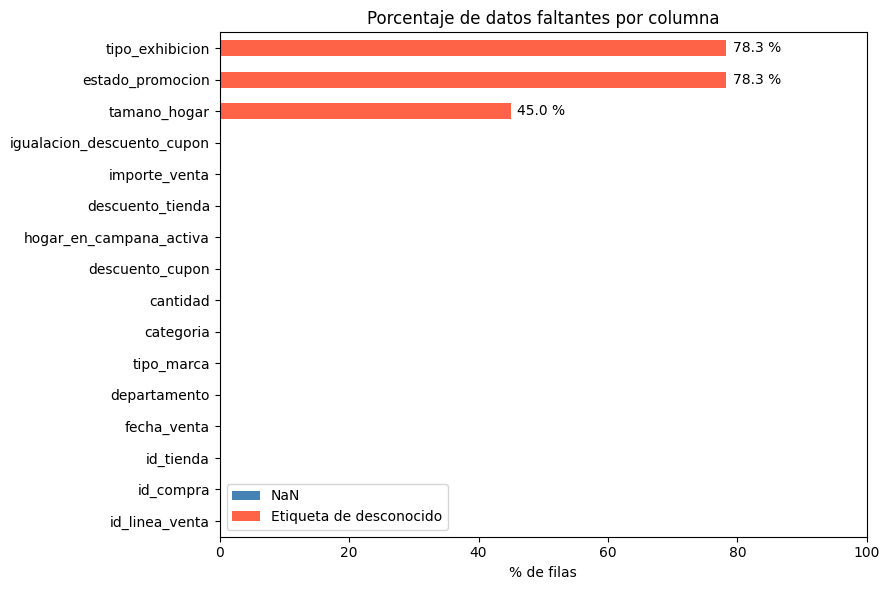

In [ ]:
porcentajes = (100 * tabla_nulos[["nulos_NaN", "nulos_disfrazados"]] / len(ventas))
porcentajes = porcentajes.sort_values("nulos_disfrazados")

ax = porcentajes.plot.barh(stacked=True, figsize=(9, 6), color=["steelblue", "tomato"])
ax.set_title("Porcentaje de datos faltantes por columna")
ax.set_xlabel("% de filas")
ax.set_xlim(0, 100)
ax.legend(["NaN", "Etiqueta de desconocido"])
for barra, valor in zip(ax.containers[1], porcentajes.sum(axis=1)):
    if valor > 0:
        ax.text(valor + 1, barra.get_y() + barra.get_height() / 2,
                f"{valor:.1f} %", va="center")
plt.tight_layout()
plt.show()

Para tratarlos como faltantes, las etiquetas de desconocido se reemplazan por `NaN`.
El siguiente gráfico muestra una muestra de 300 filas: cada franja oscura es un valor faltante.

tamano_hogar        1168429
estado_promocion    2031958
tipo_exhibicion     2031958
dtype: int64


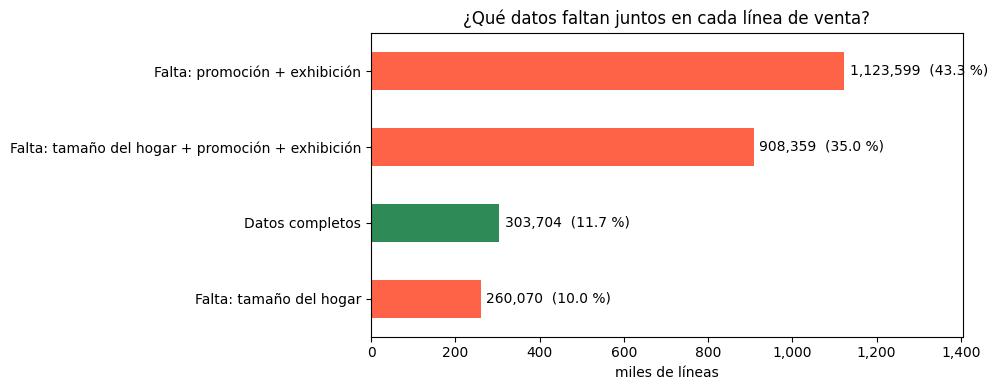

In [ ]:
for columna, etiquetas in etiquetas_desconocido.items():
    ventas[columna] = ventas[columna].mask(ventas[columna].isin(etiquetas))

print(ventas.isna().sum()[lambda s: s > 0])

nombres_cortos = {
    "tamano_hogar": "tamaño del hogar",
    "estado_promocion": "promoción",
    "tipo_exhibicion": "exhibición",
}
faltantes = ventas[list(nombres_cortos)].isna()


def describir_patron(fila):
    faltan = [nombres_cortos[c] for c, falta in fila.items() if falta]
    return "Datos completos" if not faltan else "Falta: " + " + ".join(faltan)


patrones = faltantes.value_counts()
patrones.index = [describir_patron(pd.Series(p, index=faltantes.columns)) for p in patrones.index]
patrones = patrones.sort_values()

ax = patrones.plot.barh(figsize=(10, 4), color=["tomato" if "Falta" in i else "seagreen"
                                                for i in patrones.index])
ax.set_title("¿Qué datos faltan juntos en cada línea de venta?")
ax.set_xlabel("miles de líneas")
ax.xaxis.set_major_formatter(lambda x, _: f"{x / 1000:,.0f}")
ax.bar_label(ax.containers[0], padding=4,
             labels=[f"{v:,.0f}  ({100 * v / len(ventas):.1f} %)" for v in patrones])
ax.margins(x=0.25)
plt.tight_layout()
plt.show()

**Hallazgos.**

* No existen `NaN` en el archivo original, pero sí faltan datos.
* `tamano_hogar` no tiene perfil demográfico en el **45 %** de las líneas (1 168 429).
* `estado_promocion` y `tipo_exhibicion` no tienen dato en el **78 %** (2 031 958) y faltan **en las mismas filas**.
  Esto indica que el faltante no es aleatorio: corresponde a ventas para las que el Data Warehouse no tiene
  información causal (promoción y exhibición) de esa tienda y semana.
* El tratamiento se define en la sección 6.

## 5. Valores atípicos

Se usa el criterio del rango intercuartílico (IQR): un valor es atípico si está por debajo de
Q1 − 1.5·IQR o por encima de Q3 + 1.5·IQR. También se revisan registros inconsistentes (cantidad 0).

In [ ]:
columnas_numericas = [
    "cantidad",
    "importe_venta",
    "descuento_tienda",
    "descuento_cupon",
    "igualacion_descuento_cupon",
]


def resumen_atipicos_iqr(tabla, columnas):
    """Devuelve una tabla con los límites IQR y la cantidad de atípicos por columna."""
    filas = []
    for columna in columnas:
        valores = tabla[columna].dropna()
        q1, q3 = valores.quantile([0.25, 0.75])
        iqr = q3 - q1
        inferior, superior = q1 - 1.5 * iqr, q3 + 1.5 * iqr
        atipicos = ((valores < inferior) | (valores > superior)).sum()
        filas.append({
            "columna": columna, "Q1": q1, "Q3": q3, "IQR": iqr,
            "limite_inferior": inferior, "limite_superior": superior,
            "atipicos": atipicos,
            "porcentaje": round(100 * atipicos / len(valores), 2),
        })
    return pd.DataFrame(filas).set_index("columna")


display(resumen_atipicos_iqr(ventas, columnas_numericas).round(2))

,Q1,Q3,IQR,limite_inferior,limite_superior,atipicos,porcentaje
columna,,,,,,,
cantidad,1.00,1.00,0.00,1.00,1.00,544765,20.99
importe_venta,1.29,3.49,2.20,-2.01,6.79,190644,7.34
descuento_tienda,-0.69,0.00,0.69,-1.72,1.03,206313,7.95
descuento_cupon,0.00,0.00,0.00,0.00,0.00,36422,1.40
igualacion_descuento_cupon,0.00,0.00,0.00,0.00,0.00,17449,0.67


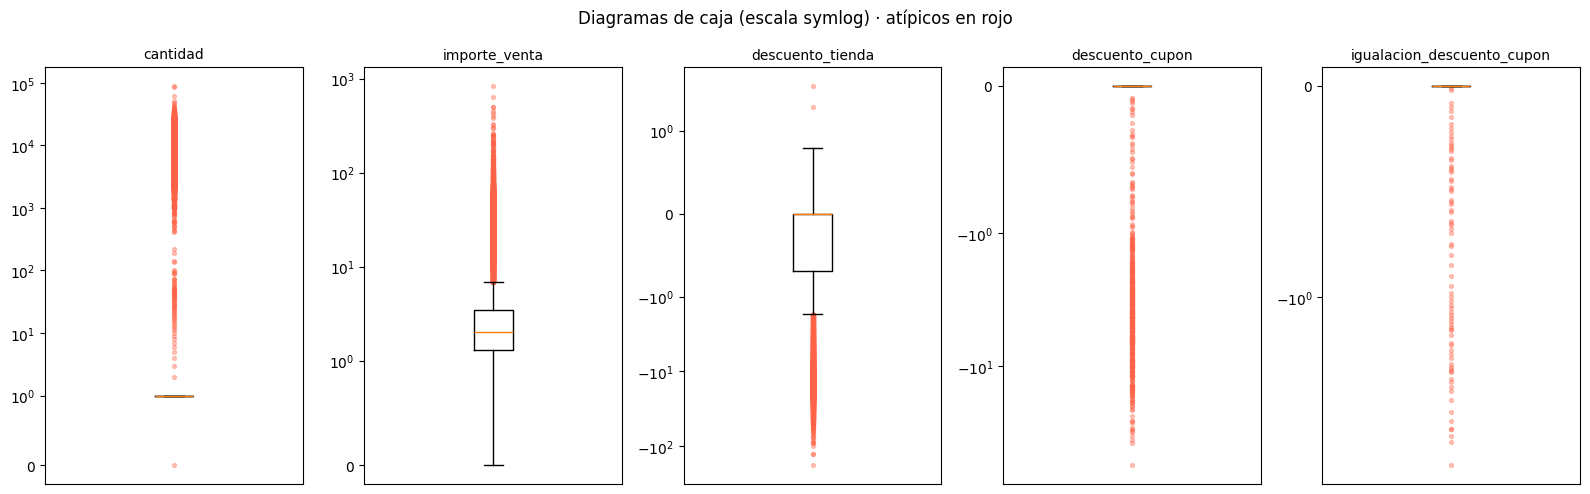

In [ ]:
fig, ejes = plt.subplots(1, len(columnas_numericas), figsize=(16, 5))

for columna, eje in zip(columnas_numericas, ejes):
    valores = ventas[columna].dropna()
    q1, q3 = valores.quantile([0.25, 0.75])
    iqr = q3 - q1
    extremos = valores[(valores < q1 - 1.5 * iqr) | (valores > q3 + 1.5 * iqr)]

    eje.boxplot(valores, showfliers=False)
    eje.scatter([1] * extremos.nunique(), extremos.unique(),
                s=8, alpha=0.35, color="tomato")
    eje.set_yscale("symlog", linthresh=1)
    eje.set_title(columna, fontsize=10)
    eje.set_xticks([])

fig.suptitle("Diagramas de caja (escala symlog) · atípicos en rojo")
plt.tight_layout()
plt.show()

In [ ]:
columnas_revision = ["id_linea_venta", "departamento", "categoria", "cantidad", "importe_venta"]
display(ventas.nlargest(10, "cantidad")[columnas_revision])

,id_linea_venta,departamento,categoria,cantidad,importe_venta
615256,615257,kiosk-gas,coupon/misc items,89638,250.00
2488029,2488030,misc sales tran,coupon/misc items,85055,210.00
614422,614423,kiosk-gas,coupon/misc items,61335,150.21
154474,154475,kiosk-gas,coupon/misc items,51912,110.00
184389,184390,kiosk-gas,coupon/misc items,48073,121.10
2187447,2187448,kiosk-gas,coupon/misc items,45475,100.00
156034,156035,kiosk-gas,coupon/misc items,41833,115.00
154688,154689,kiosk-gas,coupon/misc items,41686,100.00
1429860,1429861,misc sales tran,coupon/misc items,41485,85.00
111741,111742,kiosk-gas,coupon/misc items,39365,72.00


In [ ]:
columnas_revision = ["id_linea_venta", "departamento", "categoria", "cantidad", "importe_venta"]
display(ventas.nlargest(10, "importe_venta")[columnas_revision])

,id_linea_venta,departamento,categoria,cantidad,importe_venta
1640996,1640997,misc sales tran,coupon/misc items,3,840.00
341169,341170,drug gm,tickets,5,631.80
132888,132889,misc. trans.,no commodity description,2,505.00
375193,375194,drug gm,spring/summer seasonal,1,499.99
132813,132814,misc. trans.,no commodity description,1,455.00
2122429,2122430,misc. trans.,no commodity description,1,430.00
60911,60912,misc. trans.,no commodity description,1,400.00
2479220,2479221,misc. trans.,no commodity description,1,380.00
1136004,1136005,drug gm,spring/summer seasonal,1,329.99
2079259,2079260,floral,gift & fruit baskets,25,324.75


,median,max
departamento,,
kiosk-gas,10005.0,89638
misc sales tran,2.0,85055
produce,1.0,144
drug gm,1.0,90
grocery,1.0,60
meat,1.0,40
pastry,1.0,32
nutrition,1.0,30


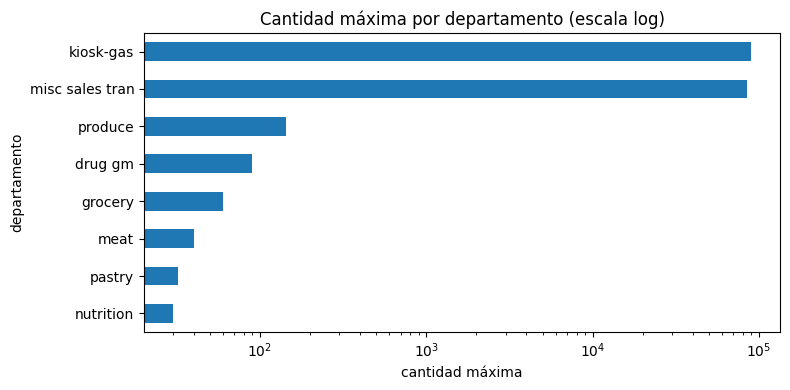

In [ ]:
# ¿En qué departamentos están las cantidades extremas?
cantidad_por_depto = (
    ventas.groupby("departamento")["cantidad"]
    .agg(["median", "max"])
    .sort_values("max", ascending=False)
    .head(8)
)
display(cantidad_por_depto)

ax = cantidad_por_depto["max"].sort_values().plot.barh(figsize=(8, 4), logx=True)
ax.set_title("Cantidad máxima por departamento (escala log)")
ax.set_xlabel("cantidad máxima")
plt.tight_layout()
plt.show()

,lineas
cantidad = 0,14466
cantidad = 0 con importe > 0,64
importe = 0,18853
importe < 0,0


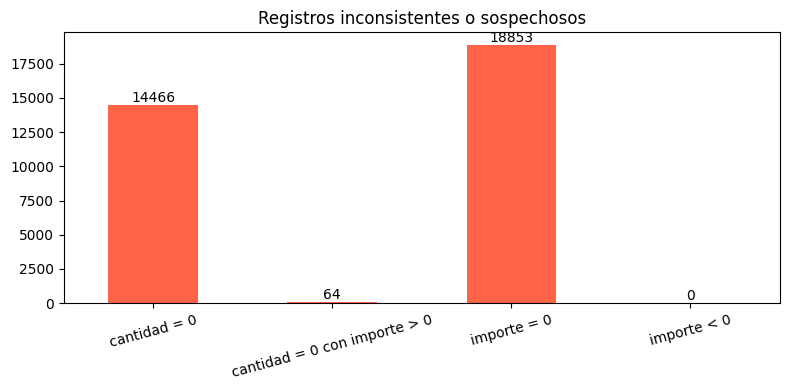

In [ ]:
inconsistentes = pd.Series({
    "cantidad = 0": (ventas["cantidad"] == 0).sum(),
    "cantidad = 0 con importe > 0": ((ventas["cantidad"] == 0) & (ventas["importe_venta"] > 0)).sum(),
    "importe = 0": (ventas["importe_venta"] == 0).sum(),
    "importe < 0": (ventas["importe_venta"] < 0).sum(),
})
display(inconsistentes.to_frame("lineas"))

ax = inconsistentes.plot.bar(figsize=(8, 4), rot=15, color="tomato")
ax.set_title("Registros inconsistentes o sospechosos")
ax.bar_label(ax.containers[0], fmt="%d")
plt.tight_layout()
plt.show()

**Hallazgos.**

* En `cantidad`, Q1 = Q3 = 1, así que el IQR es 0 y cualquier valor distinto de 1 sale como atípico.
  Por eso el IQR no sirve aquí y se usan percentiles (sección 6).
* Las cantidades extremas (hasta ~90 000) vienen de `kiosk-gas` y `misc sales tran`: la unidad no es
  comparable con la del resto de productos (por ejemplo, combustible).
* En los descuentos, la mayoría de valores es 0, así que el IQR también marca como atípico cualquier descuento.
  Esos valores son reales y se conservan.
* Hay 14 466 líneas con `cantidad = 0`, lo cual es inconsistente para una venta. Se tratarán como faltantes.
* Las 18 850 líneas con `importe_venta = 0` son productos con descuento total. Son válidas y se conservan.

## 6. Funciones de imputación

Decisiones y justificación:

| Hallazgo | Tratamiento | Justificación |
|---|---|---|
| `tamano_hogar` sin perfil (45 %) | Categoría constante **"Desconocido"** + indicador `sin_perfil_demografico` | Faltan demasiados datos: imputar la moda (hogar de 2) inventaría el tamaño de casi la mitad de los hogares y sesgaría la variable. |
| `estado_promocion` y `tipo_exhibicion` sin dato (78 %) | Categoría constante **"Sin dato"** + indicador `sin_dato_causal` | El faltante no es aleatorio (falta la información causal completa). El indicador conserva esa información para el modelo. |
| `cantidad = 0` (14 466) | Convertir a `NaN` e imputar con la **mediana de su categoría** | Una venta no puede tener cantidad 0. La mediana por categoría respeta las unidades de cada producto y no es sensible a extremos. |
| `cantidad` extrema | **Recorte (winsorización) a los percentiles 1 y 99** | El IQR es 0 en esta columna. Recortar limita el efecto de las unidades no comparables (combustible) sin borrar filas. |
| `importe_venta` y descuentos extremos | **Se conservan** | Son valores reales. `importe_venta` es la variable objetivo y recortarla sesgaría el modelo. |

In [ ]:
def imputar_categorica(tabla, columna, estrategia="constante", valor="Desconocido",
                       indicador=None):
    """Imputa los NaN de una columna categórica.

    estrategia = "constante": reemplaza por `valor`.
    estrategia = "moda": reemplaza por el valor más frecuente.
    Si se da `indicador`, crea una columna 0/1 que marca las filas imputadas.
    """
    faltantes = tabla[columna].isna()
    if indicador:
        tabla[indicador] = faltantes.astype("int8")

    relleno = tabla[columna].mode()[0] if estrategia == "moda" else valor
    tabla[columna] = tabla[columna].fillna(relleno)
    return int(faltantes.sum())


def imputar_mediana_por_grupo(tabla, columna, grupo):
    """Imputa los NaN de una columna numérica con la mediana de su grupo.

    Si un grupo no tiene ningún valor, se usa la mediana global.
    """
    faltantes = tabla[columna].isna()
    if not faltantes.any():
        return 0

    medianas = tabla.groupby(grupo, observed=True)[columna].transform("median")
    tabla[columna] = tabla[columna].fillna(medianas).fillna(tabla[columna].median())
    return int(faltantes.sum())


def recortar_atipicos(tabla, columna, inferior=0.01, superior=0.99):
    """Winsoriza una columna: lleva los valores fuera de los percentiles a esos límites."""
    limite_inf, limite_sup = tabla[columna].quantile([inferior, superior])
    fuera = ((tabla[columna] < limite_inf) | (tabla[columna] > limite_sup)).sum()
    tabla[columna] = tabla[columna].clip(limite_inf, limite_sup)
    return int(fuera), limite_inf, limite_sup

In [ ]:
nulos_antes = ventas.isna().sum()

# 1) Nulos disfrazados en variables categóricas
n = imputar_categorica(ventas, "tamano_hogar", valor="Desconocido",
                       indicador="sin_perfil_demografico")
print(f"tamano_hogar: {n:,} valores imputados con 'Desconocido'")

n = imputar_categorica(ventas, "estado_promocion", valor="Sin dato",
                       indicador="sin_dato_causal")
print(f"estado_promocion: {n:,} valores imputados con 'Sin dato'")

n = imputar_categorica(ventas, "tipo_exhibicion", valor="Sin dato")
print(f"tipo_exhibicion: {n:,} valores imputados con 'Sin dato'")

# 2) Cantidad 0 -> NaN -> mediana de su categoría
ventas["cantidad"] = ventas["cantidad"].mask(ventas["cantidad"] == 0)
nulos_antes["cantidad"] = ventas["cantidad"].isna().sum()
n = imputar_mediana_por_grupo(ventas, "cantidad", "categoria")
print(f"cantidad: {n:,} valores en 0 imputados con la mediana de su categoría")

# 3) Atípicos extremos de cantidad -> recorte P1-P99
n, li, ls = recortar_atipicos(ventas, "cantidad")
print(f"cantidad: {n:,} valores recortados al rango [{li:.0f}, {ls:.0f}]")

nulos_despues = ventas.isna().sum()
print("Nulos restantes en el conjunto:", nulos_despues.sum())

In [ ]:
comparacion = pd.DataFrame({"antes": nulos_antes, "después": nulos_despues})
comparacion = comparacion[comparacion.sum(axis=1) > 0]

ax = comparacion.plot.bar(figsize=(8, 4), rot=0, color=["tomato", "seagreen"])
ax.set_title("Valores faltantes antes y después de imputar")
ax.set_ylabel("líneas")
for contenedor in ax.containers:
    ax.bar_label(contenedor, fmt="%d", fontsize=8)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(6, 4))
ax.boxplot(ventas["cantidad"])
ax.set_title("cantidad después de imputar y recortar")
ax.set_xticks([])
plt.tight_layout()
plt.show()

## 7. Conversión de tipos de datos

* `fecha_venta` pasa de texto a `datetime` y de ella se extraen año, mes y día de la semana.
* Los identificadores (`id_linea_venta`, `id_compra`, `id_tienda`) son códigos, no cantidades:
  se convierten a texto para que no entren en cálculos numéricos.
* Las variables de texto con pocos valores distintos se convierten a `category`, lo que además reduce memoria.
* `cantidad` vuelve a entero después de la imputación.

In [ ]:
memoria_antes = ventas.memory_usage(deep=True).sum() / 1024**2

ventas["fecha_venta"] = pd.to_datetime(ventas["fecha_venta"], format="%Y-%m-%d")
ventas["anio"] = ventas["fecha_venta"].dt.year.astype("int16")
ventas["mes"] = ventas["fecha_venta"].dt.month.astype("int8")
ventas["dia_semana"] = ventas["fecha_venta"].dt.dayofweek.astype("int8")  # 0 = lunes

for columna in ["id_linea_venta", "id_compra", "id_tienda"]:
    ventas[columna] = ventas[columna].astype("string")

columnas_categoricas = [
    "departamento", "tipo_marca", "categoria", "tamano_hogar",
    "estado_promocion", "tipo_exhibicion", "hogar_en_campana_activa",
]
for columna in columnas_categoricas:
    ventas[columna] = ventas[columna].astype("category")

ventas["cantidad"] = ventas["cantidad"].round().astype("int64")

memoria_despues = ventas.memory_usage(deep=True).sum() / 1024**2
print(f"Memoria: {memoria_antes:,.0f} MB -> {memoria_despues:,.0f} MB")
display(ventas.dtypes.to_frame("tipo"))

## 8. Conversión de variables categóricas a numéricas

| Variable | Valores | Técnica |
|---|---|---|
| `tipo_marca`, `hogar_en_campana_activa`, `estado_promocion` | 2 | Binaria 0/1 |
| `tamano_hogar` | 1, 2, 3, 4, 5+, Desconocido | Ordinal 1–5 (Desconocido = 0, ya marcado en `sin_perfil_demografico`) |
| `tipo_exhibicion` | 20 | One-hot (`get_dummies`) |
| `departamento`, `categoria` | 44 y 308 | Codificación por etiqueta (`cat.codes`): one-hot crearía más de 350 columnas para 2.6 millones de filas, y el árbol de regresión propuesto trabaja bien con códigos |

In [ ]:
codificadas = pd.DataFrame(index=ventas.index)

codificadas["es_marca_propia"] = (ventas["tipo_marca"] == "private").astype("int8")
codificadas["en_campana"] = (ventas["hogar_en_campana_activa"] == "In campaign").astype("int8")
codificadas["en_promocion"] = (ventas["estado_promocion"] == "Promotion").astype("int8")

orden_hogar = {"1": 1, "2": 2, "3": 3, "4": 4, "5+": 5, "Desconocido": 0}
codificadas["tamano_hogar_num"] = (
    ventas["tamano_hogar"].astype(str).map(orden_hogar).astype("int8")
)

codificadas["departamento_cod"] = ventas["departamento"].cat.codes.astype("int16")
codificadas["categoria_cod"] = ventas["categoria"].cat.codes.astype("int16")

exhibicion = pd.get_dummies(ventas["tipo_exhibicion"], prefix="exhib", dtype="int8")
exhibicion.columns = (
    exhibicion.columns.str.lower()
    .str.replace(r"[^a-z0-9]+", "_", regex=True)
    .str.strip("_")
)
codificadas = pd.concat([codificadas, exhibicion], axis=1)

print("Columnas numéricas creadas:", codificadas.shape[1])
display(codificadas.head())

## 9. Estandarización

Se aplica estandarización **z-score** (media 0, desviación estándar 1) a los predictores numéricos continuos.
Se eligió estandarizar en vez de normalizar (min-max) porque los descuentos y la cantidad tienen valores
extremos: con min-max casi todos los datos quedarían comprimidos cerca de 0.
La variable objetivo `importe_venta` no se estandariza para que el resultado del modelo quede en la unidad original.

In [ ]:
def estandarizar_z(tabla, columnas):
    """Devuelve las columnas estandarizadas (x - media) / desviación, con sufijo _z."""
    datos = tabla[columnas].astype("float64")
    return ((datos - datos.mean()) / datos.std(ddof=0)).add_suffix("_z")


columnas_a_estandarizar = [
    "cantidad", "descuento_tienda", "descuento_cupon", "igualacion_descuento_cupon",
]
estandarizadas = estandarizar_z(ventas, columnas_a_estandarizar)

display(pd.DataFrame({
    "media": estandarizadas.mean(),
    "desviacion_estandar": estandarizadas.std(ddof=0),
}).round(3))

fig, ejes = plt.subplots(1, 2, figsize=(11, 4))
ventas["descuento_tienda"].plot.hist(bins=60, ax=ejes[0], log=True)
ejes[0].set_title("descuento_tienda (original)")
estandarizadas["descuento_tienda_z"].plot.hist(bins=60, ax=ejes[1], log=True, color="seagreen")
ejes[1].set_title("descuento_tienda_z (estandarizado)")
plt.tight_layout()
plt.show()

In [ ]:
ventas_procesadas = pd.concat([ventas, codificadas, estandarizadas], axis=1)
print("Filas y columnas:", ventas_procesadas.shape)

## 10. Correlación

Se calcula la correlación de Pearson entre la variable objetivo y los predictores numéricos y codificados.

In [ ]:
columnas_correlacion = [
    "importe_venta", "cantidad", "descuento_tienda", "descuento_cupon",
    "igualacion_descuento_cupon", "es_marca_propia", "en_promocion", "sin_dato_causal",
    "en_campana", "tamano_hogar_num", "sin_perfil_demografico", "mes", "dia_semana",
]
correlacion = ventas_procesadas[columnas_correlacion].corr(method="pearson")

fig, ax = plt.subplots(figsize=(11, 9))
imagen = ax.imshow(correlacion, cmap="coolwarm", vmin=-1, vmax=1)
posiciones = range(len(columnas_correlacion))
ax.set_xticks(posiciones, columnas_correlacion, rotation=45, ha="right")
ax.set_yticks(posiciones, columnas_correlacion)
for i in posiciones:
    for j in posiciones:
        valor = correlacion.iloc[i, j]
        ax.text(j, i, f"{valor:.2f}", ha="center", va="center", fontsize=8,
                color="white" if abs(valor) > 0.65 else "black")
ax.set_title("Matriz de correlación de Pearson")
fig.colorbar(imagen, ax=ax, label="Correlación")
plt.tight_layout()
plt.show()

In [ ]:
con_objetivo = correlacion["importe_venta"].drop("importe_venta").sort_values()
display(con_objetivo.round(3).to_frame("correlacion_con_importe_venta"))

ax = con_objetivo.plot.barh(
    figsize=(8, 5), color=np.where(con_objetivo < 0, "tomato", "steelblue")
)
ax.set_title("Correlación de cada variable con importe_venta")
ax.axvline(0, color="black", linewidth=0.8)
plt.tight_layout()
plt.show()

**Hallazgos.**

* `cantidad` es la variable con mayor relación con `importe_venta` (**r ≈ 0.48**, positiva y moderada): a más unidades, mayor importe.
* `descuento_tienda` tiene **r ≈ −0.25**. Los descuentos se registran como números negativos, así que el signo negativo significa que las líneas con mayor descuento suelen tener un importe más alto (productos más caros).
* `en_promocion` y `sin_dato_causal` tienen **r = −1**: en este conjunto, `estado_promocion` solo toma los valores *Promotion* y *Sin dato*, así que una columna es exactamente la opuesta de la otra. Para el modelo basta con usar una de las dos y evitar la multicolinealidad.
* `tamano_hogar_num` y `sin_perfil_demografico` (**r ≈ −0.78**) también son redundantes en parte, porque el código 0 del tamaño corresponde a "Desconocido".
* Las demás variables (mes, día de la semana, campaña, tipo de marca) tienen correlación lineal casi nula con el importe. Eso no descarta relaciones no lineales o por categoría, que es la razón para proponer un árbol de regresión.


## 11. Variable dependiente y modelo candidato

**Variable dependiente:** `importe_venta`, el monto cobrado en cada línea de venta.

**Tipo de problema:** como `importe_venta` es una variable **numérica continua**, el problema es de **regresión**
(no de clasificación).

**Modelo propuesto: árbol de regresión.**

* La correlación lineal de cada variable con el importe es débil o moderada (sección 10). Un modelo lineal
  no captaría bien relaciones que cambian según el producto. El árbol, en cambio, divide los datos por
  categoría, departamento, tipo de marca o promoción y estima el importe dentro de cada grupo.
* Trabaja bien con las variables codificadas por etiqueta (`categoria_cod`, `departamento_cod`) y no
  necesita que los datos estén estandarizados.
* Es interpretable: se pueden leer las reglas que llevan a cada predicción.

**Modelo de referencia:** una **regresión lineal múltiple** con las variables estandarizadas, para comparar
el error del árbol contra un modelo simple.

**Precaución:** los descuentos se registran en el mismo momento de la venta. Si el objetivo es predecir el
importe *antes* de la compra, habría que excluirlos para no filtrar información del resultado.

## 12. Guardado del conjunto de datos procesado

Se guarda el resultado con todas las actividades del EDA aplicadas: nombres en español, faltantes imputados,
atípicos tratados, tipos convertidos, variables codificadas y estandarizadas.

In [ ]:
ventas_procesadas.to_csv("data_process.csv", index=False)

import os
print("Archivo guardado: data_process.csv")
print("Filas y columnas:", ventas_procesadas.shape)
print(f"Tamaño: {os.path.getsize('data_process.csv') / 1024**2:,.0f} MB")
display(pd.read_csv("data_process.csv", nrows=5))

# Para descargarlo desde Colab (opcional, el archivo es grande):
# from google.colab import files
# files.download("data_process.csv")